# Email/SMS Spam Detection — End-to-End ML Project
**Day 14 | Linkific AI & Machine Learning Internship**

This notebook covers data inspection, cleaning, stratified splitting, TF-IDF, Multinomial Naive Bayes, evaluation, confusion matrix, custom predictions, and saving the trained pipeline. The included dataset is a small hand-crafted practice dataset; do not interpret its scores as real-world performance.

## 1. Import libraries and load data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay
import joblib

df = pd.read_csv("data/sms_spam_sample.csv")
display(df.head())


,label,message
0,spam,Congratulations you won a free prize claim now
1,spam,URGENT account selected for cash reward
2,spam,Win a brand new phone today click this link
3,spam,Claim your free vacation now limited offer
4,spam,Get cheap loans instantly apply now


## 2. Inspect and clean data

In [2]:
print("Shape:", df.shape)
print("Missing values:\n", df.isna().sum())
print("Class distribution:\n", df.label.value_counts())
df = df.dropna(subset=["label", "message"]).drop_duplicates().copy()
df["label"] = df["label"].str.lower().str.strip()
df["message"] = df["message"].astype(str).str.strip()
df = df[df.label.isin(["ham", "spam"])]
print("Cleaned shape:", df.shape)


Shape: (50, 2)
Missing values:
 label      0
message    0
dtype: int64
Class distribution:
 label
spam    25
ham     25
Name: count, dtype: int64
Cleaned shape: (50, 2)


## 3. Train/test split

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df.message, df.label, test_size=0.25, random_state=42, stratify=df.label
)
print(f"Training records: {len(X_train)} | Test records: {len(X_test)}")


Training records: 37 | Test records: 13


## 4. Train TF-IDF + Multinomial Naive Bayes

In [4]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2))),
    ("classifier", MultinomialNB())
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Training complete")


Training complete


## 5. Evaluate performance

,Accuracy,Spam precision,Spam recall,Spam F1-score
0,0.538,0.5,1.0,0.667


              precision    recall  f1-score   support

         ham       1.00      0.14      0.25         7
        spam       0.50      1.00      0.67         6

    accuracy                           0.54        13
   macro avg       0.75      0.57      0.46        13
weighted avg       0.77      0.54      0.44        13



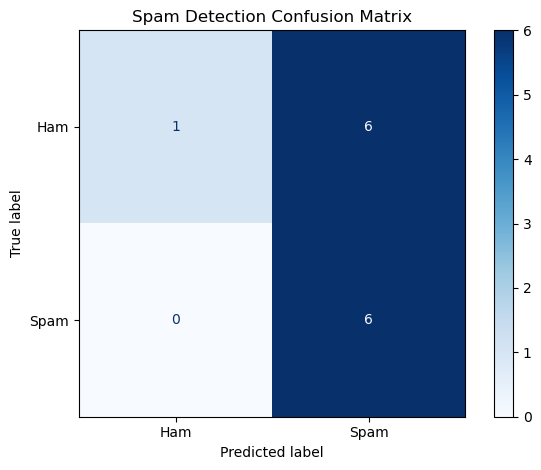

In [5]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Spam precision": precision_score(y_test, y_pred, pos_label="spam", zero_division=0),
    "Spam recall": recall_score(y_test, y_pred, pos_label="spam", zero_division=0),
    "Spam F1-score": f1_score(y_test, y_pred, pos_label="spam", zero_division=0)
}
display(pd.DataFrame([metrics]).round(3))
print(classification_report(y_test, y_pred, labels=["ham", "spam"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=["ham", "spam"], display_labels=["Ham", "Spam"], cmap="Blues")
plt.title("Spam Detection Confusion Matrix"); plt.tight_layout(); plt.show()


## 6. Try custom messages

In [6]:
samples = ["Congratulations claim your free cash prize now", "Are we meeting after class today", "URGENT limited offer click now to win"]
for message, label in zip(samples, model.predict(samples)):
    print(label.upper(), "|", message)


SPAM | Congratulations claim your free cash prize now
HAM | Are we meeting after class today
SPAM | URGENT limited offer click now to win


## 7. Save model and outputs

In [7]:
Path("outputs").mkdir(exist_ok=True)
joblib.dump(model, "outputs/spam_detection_pipeline.joblib")
pd.DataFrame({"actual": y_test.reset_index(drop=True), "predicted": y_pred}).to_csv("outputs/test_predictions.csv", index=False)
pd.DataFrame([metrics]).to_csv("outputs/evaluation_metrics.csv", index=False)
print("Saved model and evaluation outputs.")


Saved model and evaluation outputs.


## Conclusion
This project demonstrates a complete introductory text-classification workflow. Consider spam precision and recall as well as accuracy. The dataset is small and for learning only; use a larger documented dataset for meaningful estimates.